# Weather Contribution Experiment — HistGradientBoosting

This notebook compares the **same HistGradientBoostingRegressor** in two versions:

1. **With weather features**
2. **Without weather features**

The purpose is to measure the **incremental predictive contribution of weather** while keeping everything else identical.

### Weather features being tested
- `apparent_temperature`
- `rain`
- `snowfall`
- `precipitation_probability`

### Everything else stays the same
- Same Manhattan + Queens dataset
- Same chronological train/test split
- Same target: `trip_count`
- Same categorical and non-weather features
- Same HistGradientBoosting configuration
- Same evaluation metrics: MAE, RMSE, R²
- No hyperparameter tuning

This is an **ablation experiment**: the only intended change between the two models is whether weather variables are included.


## 1. Imports and configuration


In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Locate repository and load the existing train/test data


In [2]:
def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()

    for path in [start, *start.parents]:
        if (path / "models" / "modeling" / "train.csv").exists():
            return path

    raise FileNotFoundError(
        "Could not find models/modeling/train.csv. "
        "Run modeling_preparation_baseline.ipynb first."
    )

REPO_ROOT = find_repo_root()
MODELING_DIR = REPO_ROOT / "models" / "modeling"

TRAIN_PATH = MODELING_DIR / "train.csv"
TEST_PATH = MODELING_DIR / "test.csv"

train_df = pd.read_csv(TRAIN_PATH, parse_dates=["pickup_hour"])
test_df = pd.read_csv(TEST_PATH, parse_dates=["pickup_hour"])

print("Repository:", REPO_ROOT)
print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
print("Train period:", train_df["pickup_hour"].min(), "->", train_df["pickup_hour"].max())
print("Test period :", test_df["pickup_hour"].min(), "->", test_df["pickup_hour"].max())


Repository: /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting
Train shape: (460920, 17)
Test shape : (115368, 17)
Train period: 2025-09-08 00:00:00 -> 2026-01-25 03:00:00
Test period : 2026-01-25 04:00:00 -> 2026-02-28 23:00:00


## 3. Define feature groups


In [3]:
TARGET = "trip_count"

# Weather variables being tested
WEATHER_FEATURES = [
    "apparent_temperature",
    "rain",
    "snowfall",
    "precipitation_probability",
]

# Non-weather categorical variables
CATEGORICAL_FEATURES = [
    "PULocationID",
    "hour",
    "day_of_week",
    "month",
]

# Non-weather numerical variables
NON_WEATHER_NUMERICAL_FEATURES = [
    "is_holiday",
    "trip_count_lag_1h",
    "trip_count_lag_24h",
    "trip_count_lag_168h",
    "trip_count_roll_3h",
    "trip_count_roll_24h",
]

WITH_WEATHER_NUMERICAL_FEATURES = (
    NON_WEATHER_NUMERICAL_FEATURES + WEATHER_FEATURES
)

WITH_WEATHER_FEATURES = (
    CATEGORICAL_FEATURES + WITH_WEATHER_NUMERICAL_FEATURES
)

WITHOUT_WEATHER_FEATURES = (
    CATEGORICAL_FEATURES + NON_WEATHER_NUMERICAL_FEATURES
)

required_columns = [TARGET] + WITH_WEATHER_FEATURES

missing = [
    col for col in required_columns
    if col not in train_df.columns or col not in test_df.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("Weather features:", WEATHER_FEATURES)
print("With-weather feature count:", len(WITH_WEATHER_FEATURES))
print("Without-weather feature count:", len(WITHOUT_WEATHER_FEATURES))


Weather features: ['apparent_temperature', 'rain', 'snowfall', 'precipitation_probability']
With-weather feature count: 14
Without-weather feature count: 10


## 4. Validate chronology and target

Both models will use the **exact same train/test rows**.


In [4]:
assert train_df["pickup_hour"].max() < test_df["pickup_hour"].min(),     "Train/test chronology is not valid."

y_train = train_df[TARGET].copy()
y_test = test_df[TARGET].copy()

assert (y_train >= 0).all(), "Training target contains negative values."
assert (y_test >= 0).all(), "Test target contains negative values."

print("Chronological split check: passed")
print("Train rows:", len(train_df))
print("Test rows :", len(test_df))
print("Target range (train):", y_train.min(), "to", y_train.max())
print("Target range (test) :", y_test.min(), "to", y_test.max())


Chronological split check: passed
Train rows: 460920
Test rows : 115368
Target range (train): 0 to 1122
Target range (test) : 0 to 905


## 5. Helper function to build the HistGradientBoosting pipeline

The categorical variables are ordinal-encoded and explicitly marked as categorical for the estimator.

The model configuration is kept identical for both experiments.


In [5]:
def make_hgb_pipeline(numerical_features):
    try:
        ordinal_encoder = OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=np.nan,
            encoded_missing_value=np.nan,
        )
    except TypeError:
        ordinal_encoder = OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=np.nan,
        )

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ordinal", ordinal_encoder),
    ])

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])

    preprocessor = ColumnTransformer([
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
        ("numerical", numerical_pipeline, numerical_features),
    ], remainder="drop")

    # ColumnTransformer places categorical columns first.
    categorical_indices = list(range(len(CATEGORICAL_FEATURES)))

    regressor = HistGradientBoostingRegressor(
        loss="poisson",
        learning_rate=0.08,
        max_iter=200,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=1.0,
        max_bins=255,
        early_stopping=False,
        categorical_features=categorical_indices,
        random_state=RANDOM_STATE,
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor),
    ])

    return pipeline


## 6. Define the two experiment datasets


In [6]:
X_train_with_weather = train_df[WITH_WEATHER_FEATURES].copy()
X_test_with_weather = test_df[WITH_WEATHER_FEATURES].copy()

X_train_without_weather = train_df[WITHOUT_WEATHER_FEATURES].copy()
X_test_without_weather = test_df[WITHOUT_WEATHER_FEATURES].copy()

print("With-weather train shape   :", X_train_with_weather.shape)
print("With-weather test shape    :", X_test_with_weather.shape)
print("Without-weather train shape:", X_train_without_weather.shape)
print("Without-weather test shape :", X_test_without_weather.shape)


With-weather train shape   : (460920, 14)
With-weather test shape    : (115368, 14)
Without-weather train shape: (460920, 10)
Without-weather test shape : (115368, 10)


## 7. Train model WITH weather


In [7]:
model_with_weather = make_hgb_pipeline(WITH_WEATHER_NUMERICAL_FEATURES)

print("Training HistGradientBoosting WITH weather features...")
model_with_weather.fit(X_train_with_weather, y_train)

train_pred_with_weather = np.clip(
    model_with_weather.predict(X_train_with_weather),
    0,
    None,
)

test_pred_with_weather = np.clip(
    model_with_weather.predict(X_test_with_weather),
    0,
    None,
)

print("Training completed.")
print("Test prediction range:",
      test_pred_with_weather.min(),
      "to",
      test_pred_with_weather.max())


Training HistGradientBoosting WITH weather features...
Training completed.
Test prediction range: 0.004924904805767611 to 861.8543028536905


## 8. Train model WITHOUT weather


In [8]:
model_without_weather = make_hgb_pipeline(NON_WEATHER_NUMERICAL_FEATURES)

print("Training HistGradientBoosting WITHOUT weather features...")
model_without_weather.fit(X_train_without_weather, y_train)

train_pred_without_weather = np.clip(
    model_without_weather.predict(X_train_without_weather),
    0,
    None,
)

test_pred_without_weather = np.clip(
    model_without_weather.predict(X_test_without_weather),
    0,
    None,
)

print("Training completed.")
print("Test prediction range:",
      test_pred_without_weather.min(),
      "to",
      test_pred_without_weather.max())


Training HistGradientBoosting WITHOUT weather features...
Training completed.
Test prediction range: 0.0041546593475490345 to 893.2936253588933


## 9. Evaluate both models


In [9]:
def calculate_metrics(y_true, y_pred, dataset):
    return {
        "dataset": dataset,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "rows": len(y_true),
    }

results = pd.DataFrame([
    {
        "model": "HistGradientBoosting - With Weather",
        **calculate_metrics(y_train, train_pred_with_weather, "train"),
    },
    {
        "model": "HistGradientBoosting - With Weather",
        **calculate_metrics(y_test, test_pred_with_weather, "test"),
    },
    {
        "model": "HistGradientBoosting - Without Weather",
        **calculate_metrics(y_train, train_pred_without_weather, "train"),
    },
    {
        "model": "HistGradientBoosting - Without Weather",
        **calculate_metrics(y_test, test_pred_without_weather, "test"),
    },
])

display(
    results.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}",
    })
)


,model,dataset,MAE,RMSE,R2,rows
0,HistGradientBoosting - With Weather,train,5.5382,12.8706,0.9725,460920
1,HistGradientBoosting - With Weather,test,5.7841,13.1632,0.9633,115368
2,HistGradientBoosting - Without Weather,train,5.5360,12.8914,0.9724,460920
3,HistGradientBoosting - Without Weather,test,5.6739,12.9406,0.9646,115368


## 10. Direct weather contribution comparison on the test set


In [12]:
test_results = results[results["dataset"] == "test"].set_index("model")

with_weather = test_results.loc[
    "HistGradientBoosting - With Weather"
]
without_weather = test_results.loc[
    "HistGradientBoosting - Without Weather"
]

comparison = pd.DataFrame({
    "metric": ["MAE", "RMSE", "R2"],
    "with_weather": [
        with_weather["MAE"],
        with_weather["RMSE"],
        with_weather["R2"],
    ],
    "without_weather": [
        without_weather["MAE"],
        without_weather["RMSE"],
        without_weather["R2"],
    ],
})

# For MAE/RMSE, lower is better.
# For R2, higher is better.
comparison["difference_with_minus_without"] = (
    comparison["with_weather"] - comparison["without_weather"]
)

comparison["percentage_change_from_without_weather"] = np.nan
comparison.loc[
    comparison["metric"].isin(["MAE", "RMSE"]),
    "percentage_change_from_without_weather"
] = (
    (
        comparison.loc[
            comparison["metric"].isin(["MAE", "RMSE"]),
            "without_weather"
        ]
        - comparison.loc[
            comparison["metric"].isin(["MAE", "RMSE"]),
            "with_weather"
        ]
    )
    / comparison.loc[
        comparison["metric"].isin(["MAE", "RMSE"]),
        "without_weather"
    ] * 100
)

comparison.loc[
    comparison["metric"] == "R2",
    "percentage_change_from_without_weather"
] = (
    (
        comparison.loc[
            comparison["metric"] == "R2",
            "with_weather",
        ].iloc[0]
        - comparison.loc[
            comparison["metric"] == "R2",
            "without_weather",
        ].iloc[0]
    )
    / abs(
        comparison.loc[
            comparison["metric"] == "R2",
            "without_weather",
        ].iloc[0]
    )
    * 100
)

display(
    comparison.style.format({
        "with_weather": "{:.4f}",
        "without_weather": "{:.4f}",
        "difference_with_minus_without": "{:.4f}",
        "percentage_change_from_without_weather": "{:.2f}%",
    })
)


,metric,with_weather,without_weather,difference_with_minus_without,percentage_change_from_without_weather
0,MAE,5.7841,5.6739,0.1102,-1.94%
1,RMSE,13.1632,12.9406,0.2226,-1.72%
2,R2,0.9633,0.9646,-0.0012,-0.13%


## 11. Interpret the weather contribution

Use the **test-set** results, not the training results.

### Interpretation logic

- If weather **reduces MAE and RMSE** and increases R² → weather improves prediction.
- If the changes are tiny → weather adds little incremental predictive value.
- If weather makes the metrics slightly worse → weather does not improve this particular model under the current feature set.

Do **not** interpret this experiment as a causal test. It measures predictive contribution.


## 12. Prediction error comparison by hour


,hour,with_weather_MAE,without_weather_MAE,actual_mean,MAE_improvement
0,0,4.890142,4.683997,23.429028,-0.206144
1,1,3.191696,3.108995,15.413257,-0.082701
2,2,2.315988,2.278065,10.358269,-0.037923
3,3,1.931661,1.911798,7.245951,-0.019863
4,4,2.103617,2.090742,5.827122,-0.012874
5,5,2.345670,2.351837,6.593375,0.006167
6,6,3.586048,3.566102,13.307660,-0.019946
7,7,5.523140,5.447648,23.934990,-0.075492
8,8,5.975911,5.734329,31.528157,-0.241582
9,9,5.985357,5.709484,32.663975,-0.275874


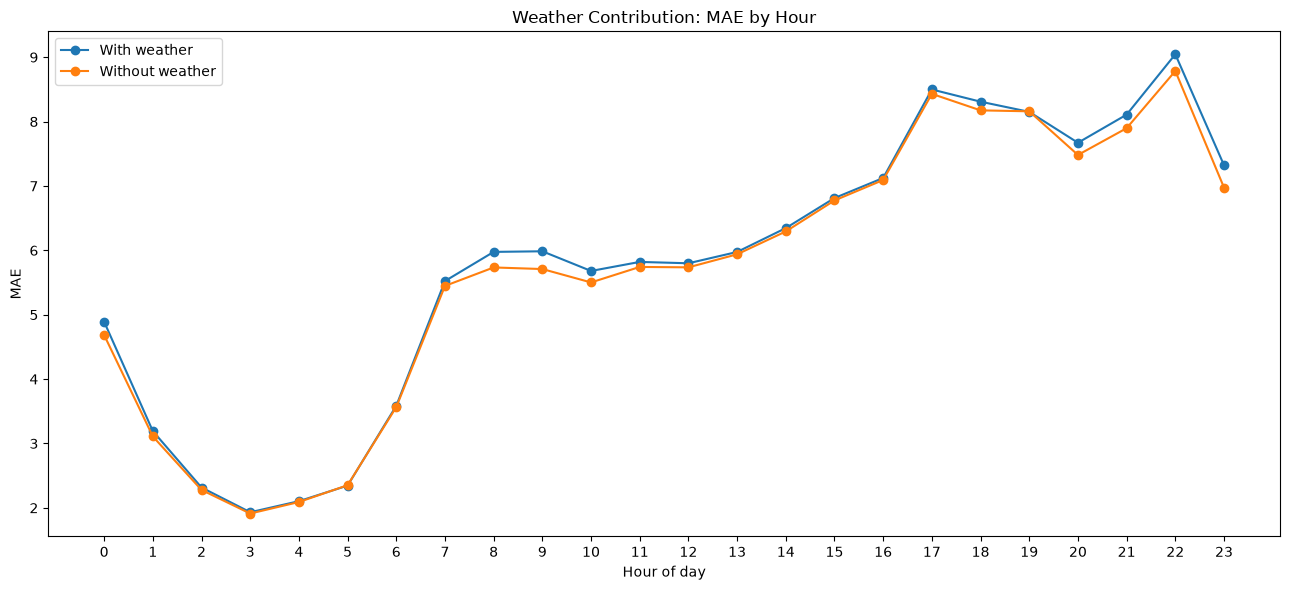

In [15]:
hourly_comparison = test_df[[
    "PULocationID",
    "pickup_hour",
    "trip_count",
]].copy()

hourly_comparison["hour"] = hourly_comparison["pickup_hour"].dt.hour

hourly_comparison["with_weather_abs_error"] = (
    hourly_comparison["trip_count"] - test_pred_with_weather
).abs()

hourly_comparison["without_weather_abs_error"] = (
    hourly_comparison["trip_count"] - test_pred_without_weather
).abs()

hourly_comparison = (
    hourly_comparison
    .groupby("hour")
    .agg(
        with_weather_MAE=("with_weather_abs_error", "mean"),
        without_weather_MAE=("without_weather_abs_error", "mean"),
        actual_mean=("trip_count", "mean"),
    )
    .reset_index()
)

hourly_comparison["MAE_improvement"] = (
    hourly_comparison["without_weather_MAE"]
    - hourly_comparison["with_weather_MAE"]
)

display(hourly_comparison)

plt.figure(figsize=(13, 6))
plt.plot(
    hourly_comparison["hour"],
    hourly_comparison["with_weather_MAE"],
    marker="o",
    label="With weather",
)
plt.plot(
    hourly_comparison["hour"],
    hourly_comparison["without_weather_MAE"],
    marker="o",
    label="Without weather",
)
plt.xlabel("Hour of day")
plt.ylabel("MAE")
plt.title("Weather Contribution: MAE by Hour")
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()


## 13. Weather contribution by pickup zone


In [16]:
zone_comparison = test_df[[
    "PULocationID",
    "trip_count",
]].copy()

zone_comparison["with_weather_abs_error"] = (
    zone_comparison["trip_count"] - test_pred_with_weather
).abs()

zone_comparison["without_weather_abs_error"] = (
    zone_comparison["trip_count"] - test_pred_without_weather
).abs()

zone_comparison = (
    zone_comparison
    .groupby("PULocationID")
    .agg(
        with_weather_MAE=("with_weather_abs_error", "mean"),
        without_weather_MAE=("without_weather_abs_error", "mean"),
        actual_mean=("trip_count", "mean"),
        observations=("trip_count", "size"),
    )
    .reset_index()
)

zone_comparison["MAE_improvement"] = (
    zone_comparison["without_weather_MAE"]
    - zone_comparison["with_weather_MAE"]
)

print("Zones where weather helps most:")
display(
    zone_comparison
    .sort_values("MAE_improvement", ascending=False)
    .head(15)
)

print("Zones where weather helps least / hurts most:")
display(
    zone_comparison
    .sort_values("MAE_improvement", ascending=True)
    .head(15)
)


Zones where weather helps most:


,PULocationID,with_weather_MAE,without_weather_MAE,actual_mean,observations,MAE_improvement
136,262,10.941612,11.002625,71.571770,836,0.061013
106,205,1.303771,1.313072,2.120813,836,0.009301
32,82,2.422050,2.427057,6.142344,836,0.005007
13,28,1.277501,1.281474,1.933014,836,0.003972
69,139,0.760688,0.763617,0.867225,836,0.002928
61,129,2.787651,2.789878,7.759569,836,0.002227
96,191,1.118338,1.120213,1.734450,836,0.001875
3,8,0.132641,0.134333,0.061005,836,0.001692
23,56,1.216814,1.218467,1.869617,836,0.001654
24,57,0.186197,0.187475,0.102871,836,0.001278


Zones where weather helps least / hurts most:


,PULocationID,with_weather_MAE,without_weather_MAE,actual_mean,observations,MAE_improvement
124,237,22.877711,21.224268,209.002392,836,-1.653444
123,236,24.191002,23.471719,200.607656,836,-0.719283
84,161,24.305525,23.599463,191.342105,836,-0.706062
72,142,22.973199,22.329557,136.226077,836,-0.643642
31,79,18.943518,18.431686,136.546651,836,-0.511831
85,162,19.755228,19.250769,141.911483,836,-0.504459
95,186,26.105488,25.635687,137.866029,836,-0.469801
129,246,15.801399,15.342914,90.069378,836,-0.458484
64,132,34.097089,33.649084,167.139952,836,-0.448005
89,170,16.137565,15.695307,125.095694,836,-0.442258


## 14. Save the weather ablation results


In [17]:
results_path = MODELING_DIR / "weather_ablation_results.csv"
comparison_path = MODELING_DIR / "weather_ablation_test_comparison.csv"
hourly_path = MODELING_DIR / "weather_ablation_by_hour.csv"
zone_path = MODELING_DIR / "weather_ablation_by_zone.csv"

results.to_csv(results_path, index=False)
comparison.to_csv(comparison_path, index=False)
hourly_comparison.to_csv(hourly_path, index=False)
zone_comparison.to_csv(zone_path, index=False)

joblib.dump(
    model_with_weather,
    MODELING_DIR / "model_3_with_weather.joblib"
)
joblib.dump(
    model_without_weather,
    MODELING_DIR / "model_3_without_weather.joblib"
)

print("Saved:")
for path in [
    results_path,
    comparison_path,
    hourly_path,
    zone_path,
    MODELING_DIR / "model_3_with_weather.joblib",
    MODELING_DIR / "model_3_without_weather.joblib",
]:
    print(" -", path)


Saved:
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/weather_ablation_results.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/weather_ablation_test_comparison.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/weather_ablation_by_hour.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/weather_ablation_by_zone.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/model_3_with_weather.joblib
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/models/modeling/model_3_without_weather.joblib


# Weather experiment complete

The key result for Review 1 is the **test-set comparison**:

**HistGradientBoosting with weather vs HistGradientBoosting without weather.**

Use this experiment to support the project's conclusion about the **incremental predictive value of weather features**. It should not be described as evidence of causality.
